In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../dataset/Telco-Customer-Churn-Cleaned.csv")

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Cleaned dataset loaded successfully!
Dataset shape: (7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(df.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [4]:
print("Customer Churn Count:")
print(df["Churn"].value_counts())

print("\nCustomer Churn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Customer Churn Count:
Churn
No     5164
Yes    1857
Name: count, dtype: int64

Customer Churn Percentage:
Churn
No     73.550776
Yes    26.449224
Name: proportion, dtype: float64


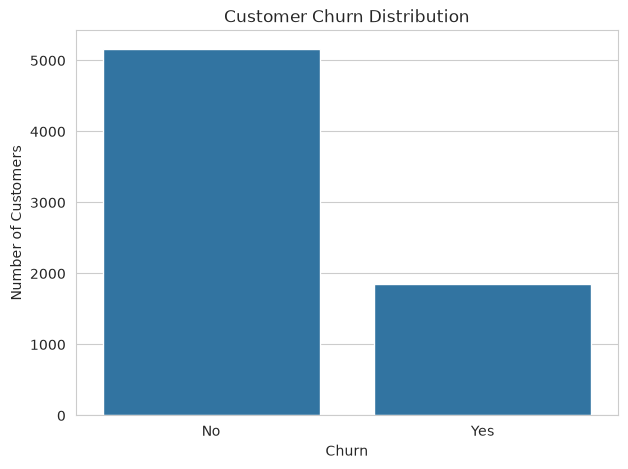

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [6]:
print("Tenure Statistics:")
print(df["tenure"].describe())

Tenure Statistics:
count    7021.000000
mean       32.469449
std        24.534965
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


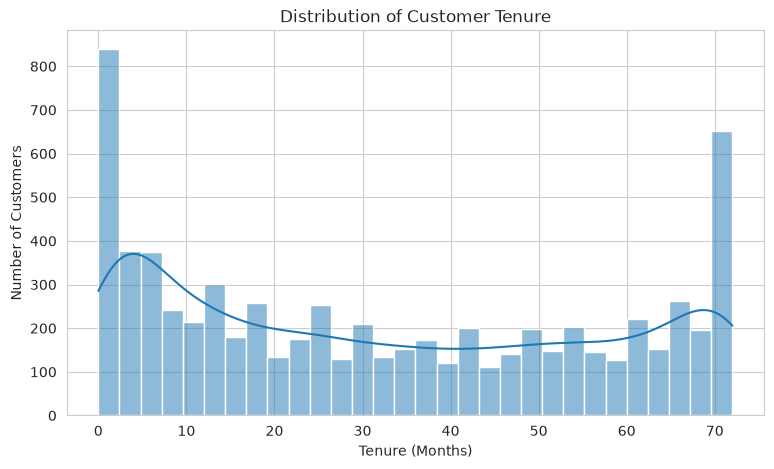

In [7]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="tenure", bins=30, kde=True)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

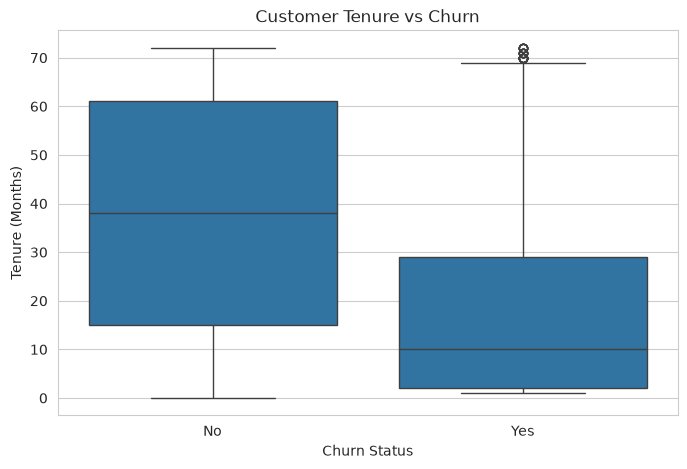

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()

In [9]:
print(
    df.groupby("Churn")["tenure"].agg(
        ["mean", "median", "min", "max"]
    )
)

            mean  median  min  max
Churn                             
No     37.640782    38.0    0   72
Yes    18.088853    10.0    1   72


In [10]:
print("Missing tenure:", df["tenure"].isnull().sum())
print("Tenure data type:", df["tenure"].dtype)

Missing tenure: 0
Tenure data type: int64


In [11]:
print("Monthly Charges Statistics:")
print(df["MonthlyCharges"].describe())

Monthly Charges Statistics:
count    7021.000000
mean       64.851894
std        30.069001
min        18.250000
25%        35.750000
50%        70.400000
75%        89.900000
max       118.750000
Name: MonthlyCharges, dtype: float64


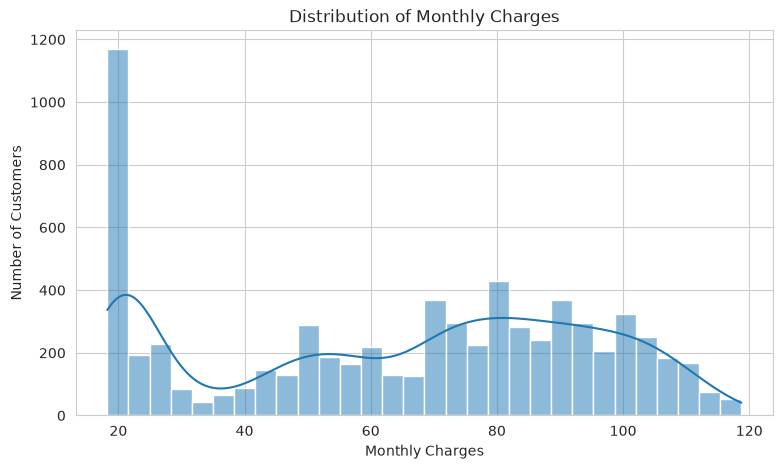

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    bins=30,
    kde=True
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

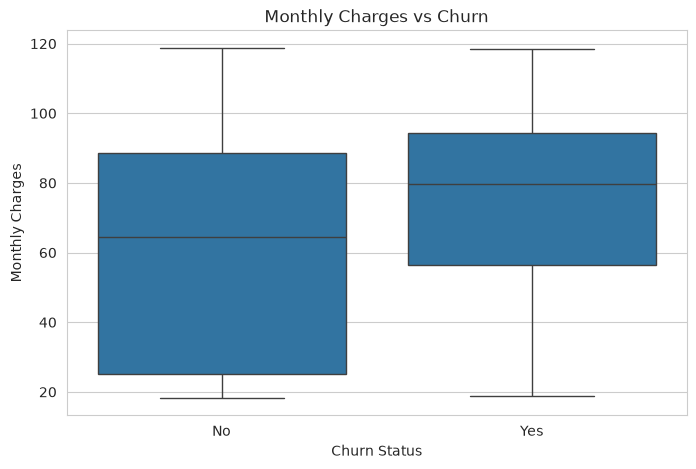

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

In [14]:
print(
    df.groupby("Churn")["MonthlyCharges"].agg(
        ["mean", "median", "min", "max"]
    )
)

            mean  median    min     max
Churn                                  
No     61.344878    64.5  18.25  118.75
Yes    74.604308    79.7  18.85  118.35


In [15]:
print("Contract Type Count:")
print(df["Contract"].value_counts())

Contract Type Count:
Contract
Month-to-month    3853
Two year          1695
One year          1473
Name: count, dtype: int64


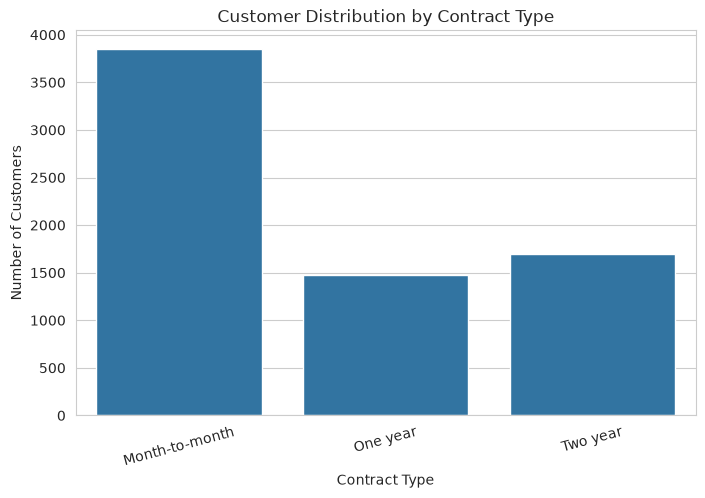

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract")

plt.title("Customer Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)

plt.show()

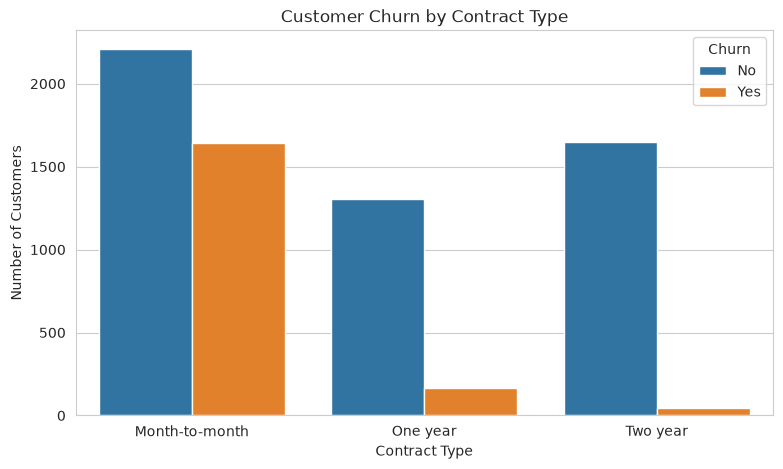

In [17]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [18]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Percentage by Contract Type:")
print(contract_churn)

Churn Percentage by Contract Type:
Churn                  No        Yes
Contract                            
Month-to-month  57.357903  42.642097
One year        88.730482  11.269518
Two year        97.168142   2.831858


In [19]:
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].isnull().sum())

tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64


In [20]:
print("Current dataset shape:", df.shape)

print("Duplicate rows:", df.duplicated().sum())

print("Contract missing values:", df["Contract"].isnull().sum())

print("Churn missing values:", df["Churn"].isnull().sum())

Current dataset shape: (7021, 20)
Duplicate rows: 0
Contract missing values: 0
Churn missing values: 0


In [21]:
print("Payment Method Count:")
print(df["PaymentMethod"].value_counts())

Payment Method Count:
PaymentMethod
Electronic check             2359
Mailed check                 1596
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


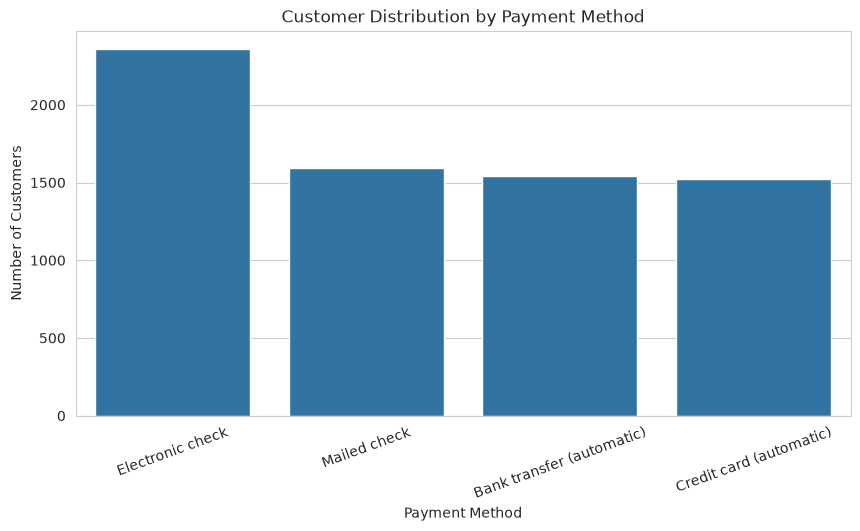

In [22]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod"
)

plt.title("Customer Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

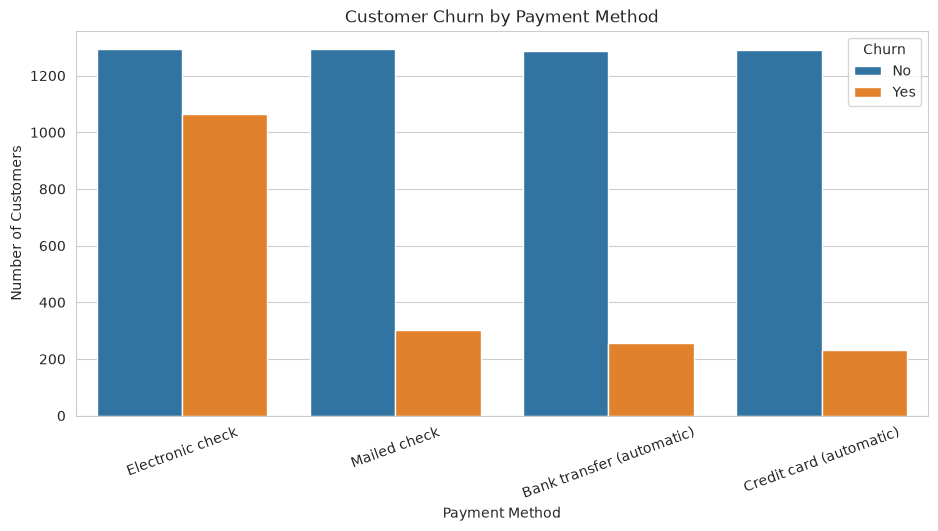

In [23]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

In [24]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Percentage by Payment Method:")
print(payment_churn)

Churn Percentage by Payment Method:
Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.853752  45.146248
Mailed check               81.077694  18.922306


In [25]:
print("Internet Service Count:")
print(df["InternetService"].value_counts())

Internet Service Count:
InternetService
Fiber optic    3090
DSL            2419
No             1512
Name: count, dtype: int64


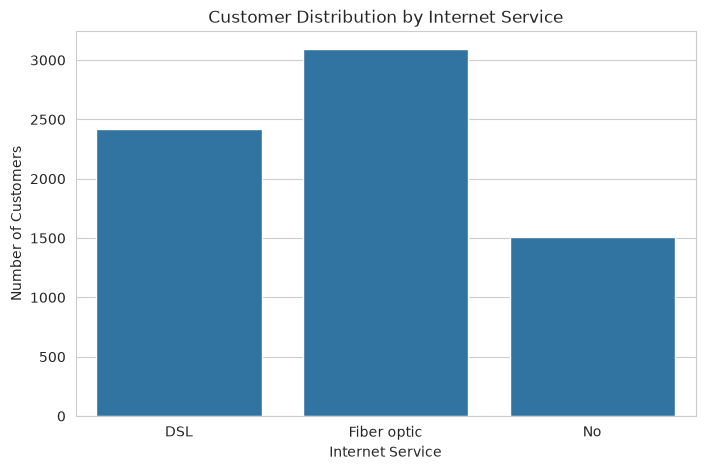

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService"
)

plt.title("Customer Distribution by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

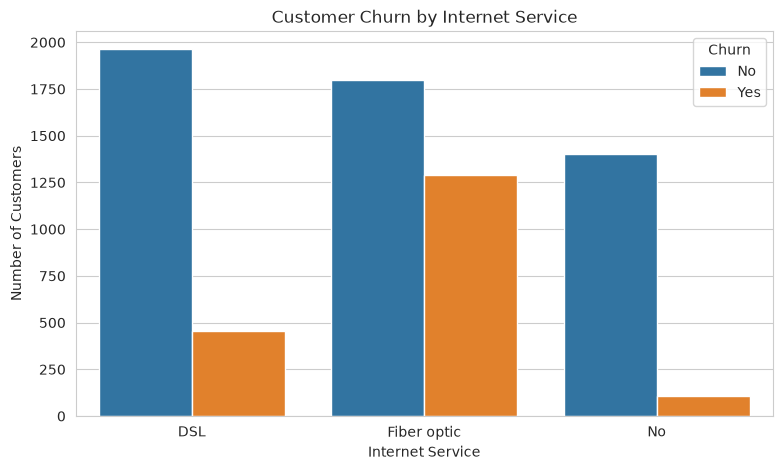

In [27]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

In [28]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Percentage by Internet Service:")
print(internet_churn)

Churn Percentage by Internet Service:
Churn                   No        Yes
InternetService                      
DSL              81.107896  18.892104
Fiber optic      58.220065  41.779935
No               92.791005   7.208995


In [29]:
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

Dataset shape: (7021, 20)
Duplicate rows: 0
Missing values: 0


In [30]:
original_df = pd.read_csv("../dataset/Telco-Customer-Churn.csv")

cleaned_df = pd.read_csv("../dataset/Telco-Customer-Churn-Cleaned.csv")

print("Original dataset shape:", original_df.shape)
print("Cleaned dataset shape:", cleaned_df.shape)

print("\nOriginal duplicate rows:",
      original_df.duplicated().sum())

print("\nOriginal blank TotalCharges:",
      original_df["TotalCharges"].astype(str).str.strip().eq("").sum())

print("\nOriginal churn distribution:")
print(original_df["Churn"].value_counts())

print("\nCleaned churn distribution:")
print(cleaned_df["Churn"].value_counts())

Original dataset shape: (7043, 21)
Cleaned dataset shape: (7021, 20)

Original duplicate rows: 0

Original blank TotalCharges: 11

Original churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Cleaned churn distribution:
Churn
No     5164
Yes    1857
Name: count, dtype: int64


In [31]:
print("Online Security Count:")
print(df["OnlineSecurity"].value_counts())

security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Online Security:")
print(security_churn)

Online Security Count:
OnlineSecurity
No                     3490
Yes                    2019
No internet service    1512
Name: count, dtype: int64

Churn Percentage by Online Security:
Churn                       No        Yes
OnlineSecurity                           
No                   58.366762  41.633238
No internet service  92.791005   7.208995
Yes                  85.388806  14.611194


In [32]:
print("Tech Support Count:")
print(df["TechSupport"].value_counts())

Tech Support Count:
TechSupport
No                     3465
Yes                    2044
No internet service    1512
Name: count, dtype: int64


In [33]:
techsupport_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Tech Support:")
print(techsupport_churn)


Churn Percentage by Tech Support:
Churn                       No        Yes
TechSupport                              
No                   58.499278  41.500722
No internet service  92.791005   7.208995
Yes                  84.833659  15.166341


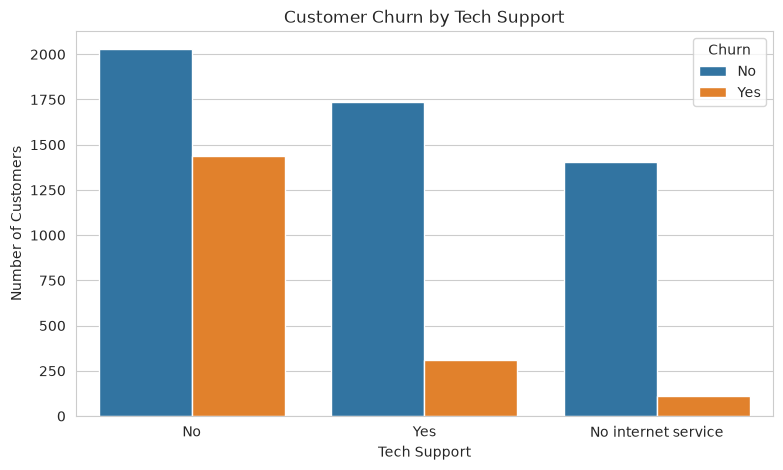

In [34]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="TechSupport",
    hue="Churn"
)

plt.title("Customer Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")

plt.show()

In [35]:
print("Paperless Billing Count:")
print(df["PaperlessBilling"].value_counts())

Paperless Billing Count:
PaperlessBilling
Yes    4161
No     2860
Name: count, dtype: int64


In [36]:
billing_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Paperless Billing:")
print(billing_churn)


Churn Percentage by Paperless Billing:
Churn                    No        Yes
PaperlessBilling                      
No                83.706294  16.293706
Yes               66.570536  33.429464


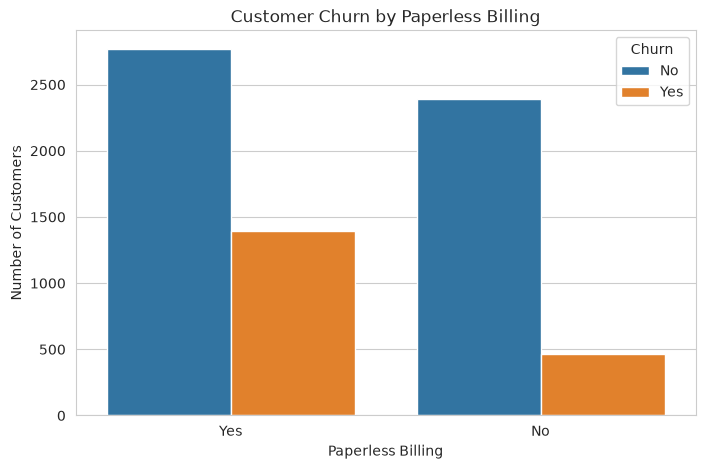

In [37]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="PaperlessBilling",
    hue="Churn"
)

plt.title("Customer Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")

plt.show()

In [38]:
print("Partner Count:")
print(df["Partner"].value_counts())

partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Partner:")
print(partner_churn)

Partner Count:
Partner
No     3619
Yes    3402
Name: count, dtype: int64

Churn Percentage by Partner:
Churn           No        Yes
Partner                      
No       67.173252  32.826748
Yes      80.335097  19.664903


In [39]:
print("Dependents Count:")
print(df["Dependents"].value_counts())

dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Dependents:")
print(dependents_churn)

Dependents Count:
Dependents
No     4911
Yes    2110
Name: count, dtype: int64

Churn Percentage by Dependents:
Churn              No        Yes
Dependents                      
No          68.825087  31.174913
Yes         84.549763  15.450237


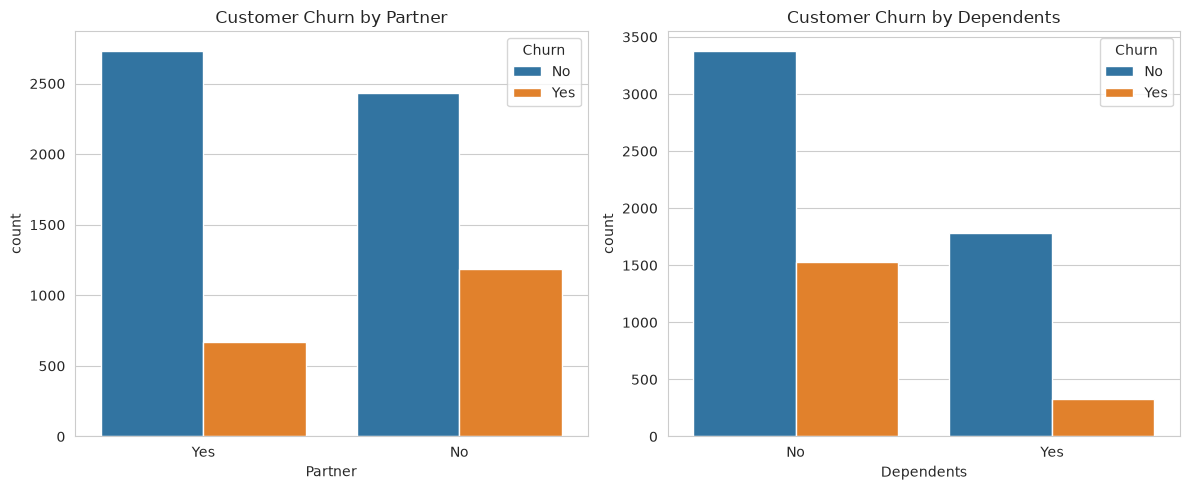

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    data=df,
    x="Partner",
    hue="Churn",
    ax=axes[0]
)

axes[0].set_title("Customer Churn by Partner")

sns.countplot(
    data=df,
    x="Dependents",
    hue="Churn",
    ax=axes[1]
)

axes[1].set_title("Customer Churn by Dependents")

plt.tight_layout()
plt.show()

In [41]:
print("Senior Citizen Count:")
print(df["SeniorCitizen"].value_counts())

Senior Citizen Count:
SeniorCitizen
0    5880
1    1141
Name: count, dtype: int64


In [42]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Senior Citizen:")
print(senior_churn)


Churn Percentage by Senior Citizen:
Churn                 No        Yes
SeniorCitizen                      
0              76.496599  23.503401
1              58.369851  41.630149


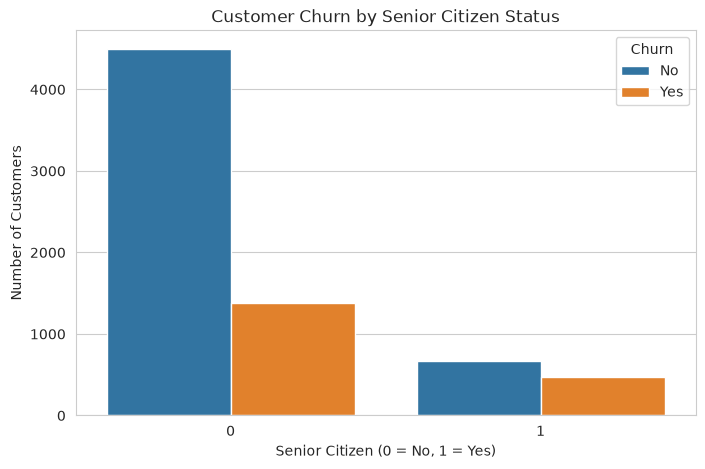

In [43]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="Churn"
)

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

In [44]:
print("Gender Count:")
print(df["gender"].value_counts())

Gender Count:
gender
Male      3541
Female    3480
Name: count, dtype: int64


In [45]:
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Gender:")
print(gender_churn)


Churn Percentage by Gender:
Churn          No        Yes
gender                      
Female  73.160920  26.839080
Male    73.933917  26.066083


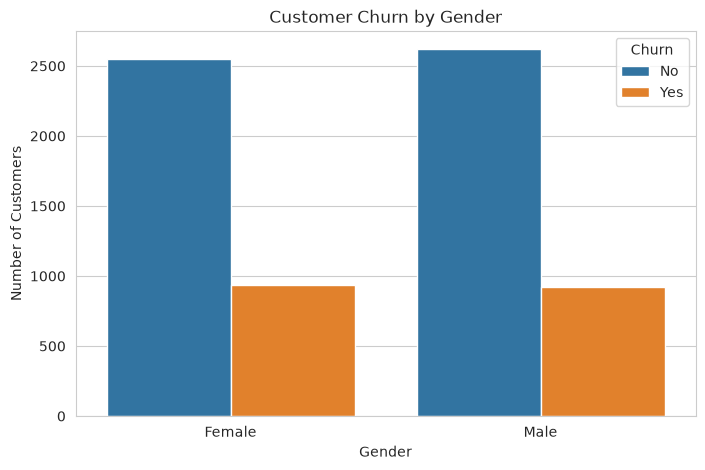

In [46]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="gender",
    hue="Churn"
)

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

In [47]:
print("Multiple Lines Count:")
print(df["MultipleLines"].value_counts())

Multiple Lines Count:
MultipleLines
No                  3368
Yes                 2971
No phone service     682
Name: count, dtype: int64


In [48]:
multiple_lines_churn = pd.crosstab(
    df["MultipleLines"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage by Multiple Lines:")
print(multiple_lines_churn)


Churn Percentage by Multiple Lines:
Churn                    No        Yes
MultipleLines                         
No                75.148456  24.851544
No phone service  75.073314  24.926686
Yes               71.390104  28.609896


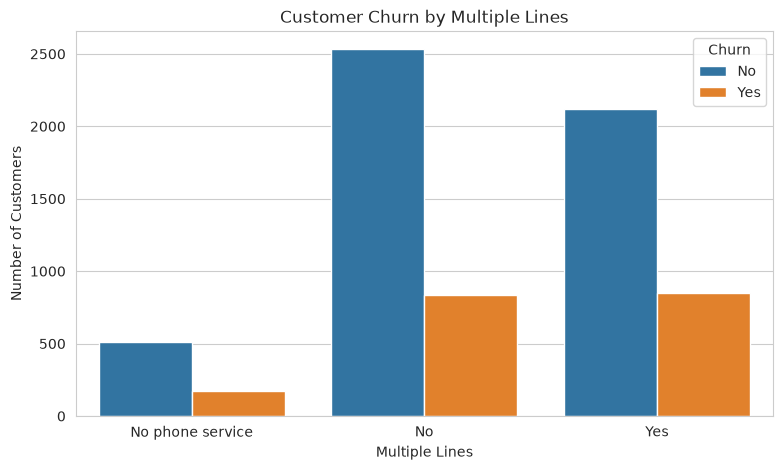

In [49]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="MultipleLines",
    hue="Churn"
)

plt.title("Customer Churn by Multiple Lines")
plt.xlabel("Multiple Lines")
plt.ylabel("Number of Customers")

plt.show()

In [50]:
service_features = [
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "PhoneService"
]

for feature in service_features:

    print("\n" + "=" * 50)
    print("Feature:", feature)

    print("\nCustomer Count:")
    print(df[feature].value_counts())

    churn_table = pd.crosstab(
        df[feature],
        df["Churn"],
        normalize="index"
    ) * 100

    print("\nChurn Percentage:")
    print(churn_table)


Feature: OnlineBackup

Customer Count:
OnlineBackup
No                     3080
Yes                    2429
No internet service    1512
Name: count, dtype: int64

Churn Percentage:
Churn                       No        Yes
OnlineBackup                             
No                   60.227273  39.772727
No internet service  92.791005   7.208995
Yes                  78.468506  21.531494

Feature: DeviceProtection

Customer Count:
DeviceProtection
No                     3087
Yes                    2422
No internet service    1512
Name: count, dtype: int64

Churn Percentage:
Churn                       No        Yes
DeviceProtection                         
No                   61.030126  38.969874
No internet service  92.791005   7.208995
Yes                  77.497936  22.502064

Feature: StreamingTV

Customer Count:
StreamingTV
No                     2802
Yes                    2707
No internet service    1512
Name: count, dtype: int64

Churn Percentage:
Churn                       

In [51]:
remaining_features = [
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies"
]

for feature in remaining_features:

    print("\n", feature)

    result = pd.crosstab(
        df[feature],
        df["Churn"],
        normalize="index"
    ) * 100

    print(result.round(2))


 DeviceProtection
Churn                   No    Yes
DeviceProtection                 
No                   61.03  38.97
No internet service  92.79   7.21
Yes                  77.50  22.50

 StreamingTV
Churn                   No    Yes
StreamingTV                      
No                   66.67  33.33
No internet service  92.79   7.21
Yes                  69.93  30.07

 StreamingMovies
Churn                   No    Yes
StreamingMovies                  
No                   66.51  33.49
No internet service  92.79   7.21
Yes                  70.06  29.94


In [52]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print(df[numerical_features].dtypes)

tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object


In [53]:
print(df[numerical_features].describe())

            tenure  MonthlyCharges  TotalCharges
count  7021.000000     7021.000000   7021.000000
mean     32.469449       64.851894   2286.765026
std      24.534965       30.069001   2266.855057
min       0.000000       18.250000      0.000000
25%       9.000000       35.750000    403.350000
50%      29.000000       70.400000   1400.550000
75%      55.000000       89.900000   3801.700000
max      72.000000      118.750000   8684.800000


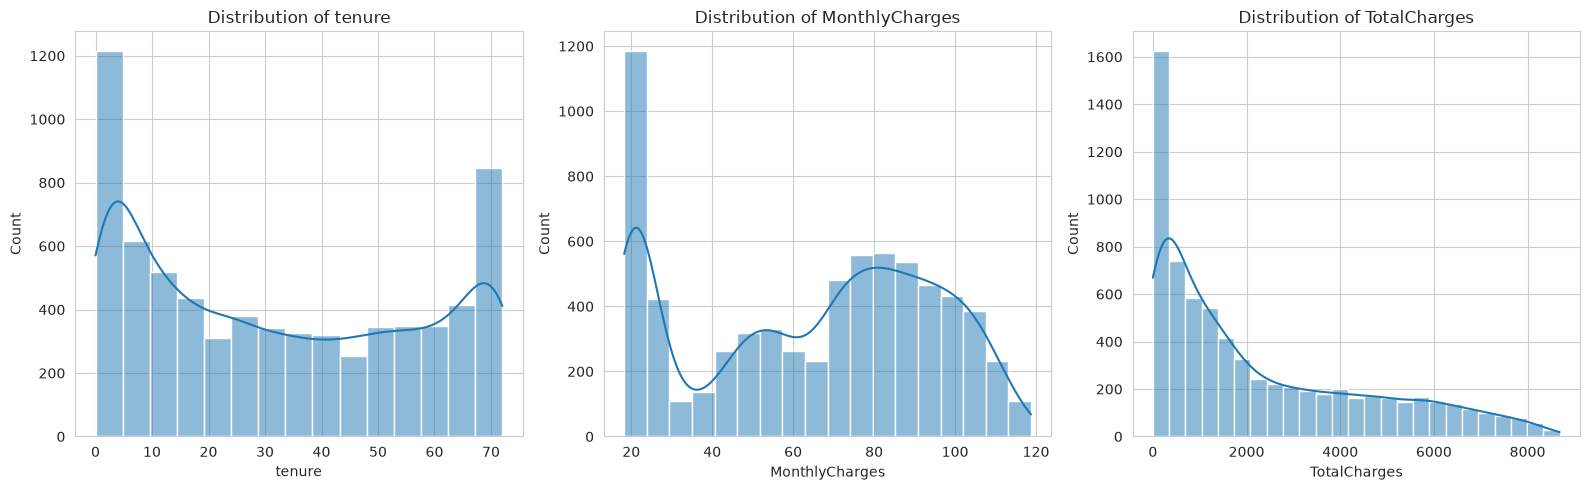

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(numerical_features):

    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

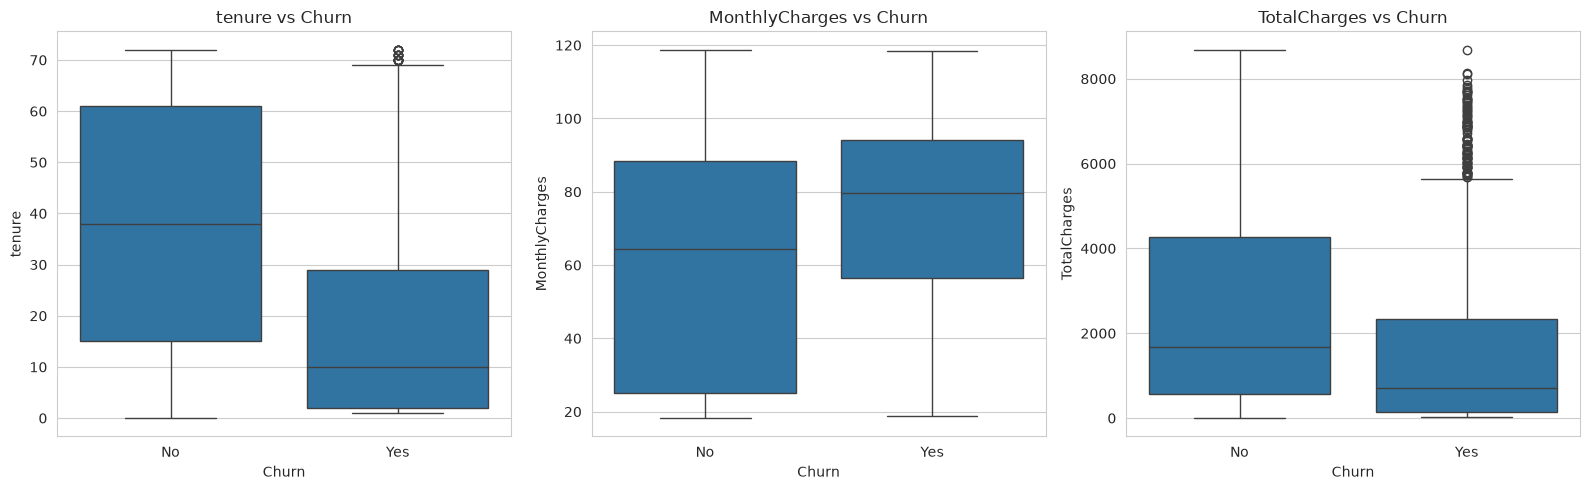

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(numerical_features):

    sns.boxplot(
        data=df,
        x="Churn",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs Churn")

plt.tight_layout()
plt.show()

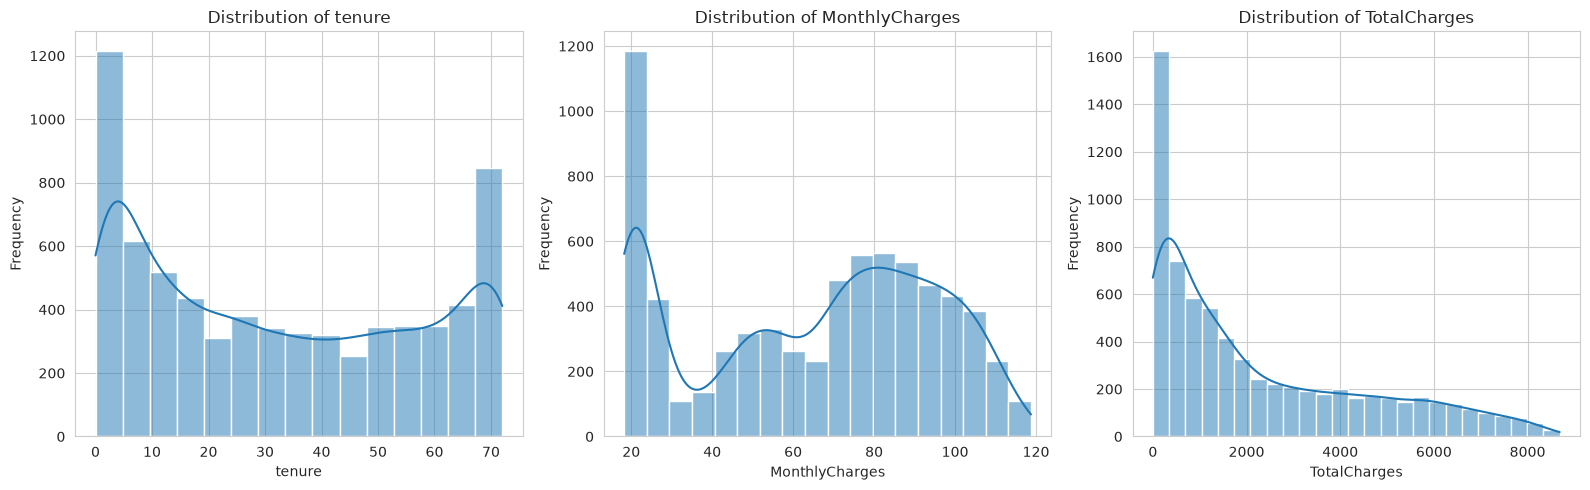

In [56]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(numerical_features):

    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [57]:
for feature in numerical_features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    print("\nFeature:", feature)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outlier Count:", len(outliers))
    print("Outlier Percentage:",
          round(len(outliers) / len(df) * 100, 2), "%")


Feature: tenure
Q1: 9.0
Q3: 55.0
IQR: 46.0
Lower Bound: -60.0
Upper Bound: 124.0
Outlier Count: 0
Outlier Percentage: 0.0 %

Feature: MonthlyCharges
Q1: 35.75
Q3: 89.9
IQR: 54.150000000000006
Lower Bound: -45.47500000000001
Upper Bound: 171.125
Outlier Count: 0
Outlier Percentage: 0.0 %

Feature: TotalCharges
Q1: 403.35
Q3: 3801.7
IQR: 3398.35
Lower Bound: -4694.174999999999
Upper Bound: 8899.224999999999
Outlier Count: 0
Outlier Percentage: 0.0 %
